# Module 14 · Presentations and individual explanations
**Applied Stochastic Processes: Modeling, Simulation, and AI**

Practical question: **Can you state what the evidence supports, reproduce its central calculation, and explain how the conclusion changes when an assumption changes?**

Guided work: about 30–40 minutes. Existing-project rehearsal: about 20–30 minutes. The presentation is six minutes plus questions. This final module adds no seventh concept lab, new project, or extra submission. Your individual or paired sustained project still uses two or three methods meaningfully; the Markov example below is one component, not a replacement for that requirement.

[Course home](../index.html) · [Interactive lesson](../modules/module14.html) · [Project guide](../project-guide.html)

Finish the existing executed notebook, 4–5-page report, one-page decision brief, and slides. Keep the question, calculations, and limitations consistent across them. This notebook is a rehearsal and evidence source, not an automatically generated slide deck. AI assistance remains optional and requires no account.

## 1. Lead with the target, units, and information boundary
Let $C_t$ be completed system-wide rentals on calendar day $t$ and $S_t=\mathbf1\{C_t\ge4000\}$. The inclusive threshold defines a **high completed-count day**, not a station shortage. The dataset does not measure inventory, unmet demand, or an intervention effect. A forecast of $P(S_t=1)$ is a probability, not a predicted number of rentals.

We reproduce Module 13: fit on January–August (243 days, 242 adjacent pairs), freeze the transition matrix, and score 122 rolling one-day September–December targets using the previous observed state. September 1 uses August 31. The year has appeared repeatedly in this course, so the later period supplies **reused development assessment**, not a new untouched final holdout.

The unchanged [UCI Bike Sharing sample](https://doi.org/10.24432/C5W894), Fanaee-T (2013), is bundled under CC BY 4.0. No observations are generated or added here. The checksum checks file identity with the recorded sample; it does not prove that the data measure the decision quantity.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib, json, platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display
plt.rcParams.update({"figure.figsize": (10, 3.8), "font.size": 11})

In [2]:
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p/"data/bike_daily_2011.csv").is_file())
data_path = ROOT/"data/bike_daily_2011.csv"
source = json.loads((ROOT/"data/source_metadata.json").read_text())
data_sha256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert data_sha256 == source["sample_sha256"] == "fb9790e24f07b237431b89c787a24ed8e97c365437a86f7161269df9452b2329"
bike = pd.read_csv(data_path, parse_dates=["dteday"])
assert bike.dteday.tolist() == list(pd.date_range("2011-01-01", "2011-12-31"))
assert bike.dteday.is_unique and bike.cnt.ge(0).all()
assert np.isfinite(bike.cnt).all() and np.all(bike.cnt == np.floor(bike.cnt))
counts = bike.cnt.to_numpy(float)
print("Verified 365 complete 2011 dates; unchanged CSV SHA-256:", data_sha256)

Verified 365 complete 2011 dates; unchanged CSV SHA-256: fb9790e24f07b237431b89c787a24ed8e97c365437a86f7161269df9452b2329


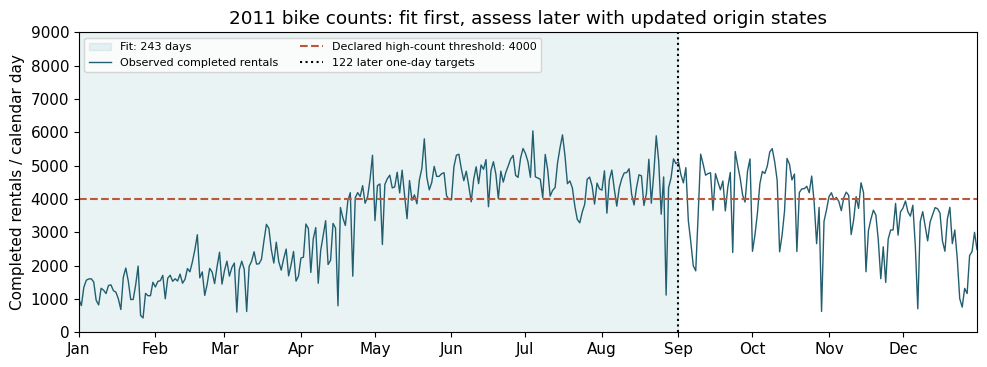

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.axvspan(pd.Timestamp("2011-01-01"), pd.Timestamp("2011-09-01"), color="#117c83", alpha=0.09, label="Fit: 243 days")
ax.plot(bike.dteday, counts, color="#225e70", linewidth=1, label="Observed completed rentals")
ax.axhline(4000, color="#bb573d", linestyle="--", label="Declared high-count threshold: 4000")
ax.axvline(pd.Timestamp("2011-09-01"), color="black", linestyle=":", label="122 later one-day targets")
ax.set(xlim=(bike.dteday.iloc[0], bike.dteday.iloc[-1]), ylim=(0, 9000), ylabel="Completed rentals / calendar day", title="2011 bike counts: fit first, assess later with updated origin states")
ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend(fontsize=8, loc="upper left", ncol=2); fig.tight_layout(); plt.show()

**Figure 1. Observed counts and declared roles.** All 365 calendar days of 2011 are shown in completed system rentals/day. The shaded January–August prefix fits the model; the 122 later targets use one-day forecasts and observed prior states. The 4000 line is an analyst-chosen state boundary, not capacity. These dates are reused development evidence, not an untouched holdout.

## 2. Show the model and one check
For $i,j\in\{0,1\}$, count only pairs within training and normalize by their originating row:
$$N_{ij}=\sum_{t=0}^{241}\mathbf1\{S_t=i,S_{t+1}=j\},\qquad \widehat P_{ij}=\frac{N_{ij}}{N_{i0}+N_{i1}}.$$
A missing outgoing row makes this estimate undefined; the helper rejects it. Each row represents a conditional next-state distribution. The equality fixture $3999,4000,4001\mapsto0,1,1$ makes the inclusive state rule explicit.

In [4]:
def high_state(values, threshold=4000):
    values = np.asarray(values, float)
    if values.ndim != 1 or not np.isfinite(values).all(): raise ValueError("Finite 1D counts required")
    if np.any(values < 0) or np.any(values != np.floor(values)): raise ValueError("Nonnegative integer counts required")
    if not np.isfinite(threshold) or threshold < 0: raise ValueError("Finite nonnegative threshold required")
    return (values >= threshold).astype(int)
def fit_transition(states):
    states = np.asarray(states)
    if states.ndim != 1 or len(states) < 2 or not np.isin(states, [0, 1]).all(): raise ValueError("Binary history required")
    N = np.zeros((2, 2), dtype=int)
    np.add.at(N, (states[:-1].astype(int), states[1:].astype(int)), 1)
    if np.any(N.sum(axis=1) == 0): raise ValueError("No outgoing observations for one training state")
    return N, N/N.sum(axis=1, keepdims=True)

In [5]:
THRESHOLD, CUTOFF = 4000, 243
states = high_state(counts, THRESHOLD)
N, P = fit_transition(states[:CUTOFF])
assert N.tolist() == [[114, 20], [19, 89]] and N.sum() == 242
assert np.allclose(P.sum(axis=1), 1)
assert high_state([3999, 4000, 4001]).tolist() == [0, 1, 1]
print("Training transition counts:", N.tolist())
display(pd.DataFrame(P, index=["Previous low", "Previous high"], columns=["Next low", "Next high"]))

Training transition counts: [[114, 20], [19, 89]]


,Next low,Next high
Previous low,0.850746,0.149254
Previous high,0.175926,0.824074


## 3. Compare a declared baseline on the same targets
For a target day $t$, the frozen chain issues $q_t=\widehat P_{S_{t-1},1}$ and persistence issues $b_t=S_{t-1}$. The target outcome is revealed **after** these forecasts are issued. The Brier loss and mean Brier score are
$$\ell(q_t,S_t)=(q_t-S_t)^2,\qquad \overline\ell=\frac1{122}\sum_{t=243}^{364}(q_t-S_t)^2.$$
The score is dimensionless squared probability error; smaller is better. It evaluates the specified binary event, not rental-count accuracy. Persistence gives probability 0 or 1 and incurs loss 1 exactly when the observed state changes.

In [6]:
def rolling_forecasts(values):
    s = high_state(values, THRESHOLD)
    fitted_N, fitted_P = fit_transition(s[:CUTOFF])
    previous, actual = s[CUTOFF-1:-1], s[CUTOFF:]
    return fitted_P, fitted_P[previous, 1], previous.astype(float), actual
frozen_P, probability, persistence, actual = rolling_forecasts(counts)
assert np.array_equal(frozen_P, P) and len(actual) == 122
chain_loss = (probability-actual)**2
baseline_loss = (persistence-actual)**2
chain_brier, baseline_brier = chain_loss.mean(), baseline_loss.mean()

### Absolute versus relative change
With baseline score $B$ and model score $M$,
$$\Delta=B-M,\qquad R=100\frac{B-M}{B}\%\quad(B>0).$$
Positive $\Delta$ favors the model on this mean loss. If $B=0$, the relative change is undefined; report the absolute difference. $R$ is a **percentage reduction in mean Brier loss**, not a percentage increase in accuracy and not a percentage-point event-probability change. A descriptive difference alone supplies no uncertainty interval or proof of future superiority.

In [7]:
def loss_comparison(model_loss, baseline_loss):
    values = np.array([model_loss, baseline_loss], float)
    if not np.isfinite(values).all() or np.any(values < 0): raise ValueError("Finite nonnegative losses required")
    absolute = baseline_loss-model_loss
    relative = np.nan if baseline_loss == 0 else 100*absolute/baseline_loss
    return absolute, relative
def probability_label(p):
    if not np.isfinite(p) or not 0 <= p <= 1: raise ValueError("Probability must be in [0,1]")
    return f"{100*p:.2f}%"
absolute_gain, relative_gain = loss_comparison(chain_brier, baseline_brier)
assert probability_label(0) == "0.00%" and probability_label(1) == "100.00%"
assert np.isnan(loss_comparison(0, 0)[1]) and np.isnan(loss_comparison(0.1, 0)[1])
print(f"Chain / persistence mean Brier loss: {chain_brier:.12f} / {baseline_brier:.12f}")
print(f"Baseline minus chain: {absolute_gain:.12f}; relative mean-loss reduction: {relative_gain:.8f}%")

Chain / persistence mean Brier loss: 0.174887057949 / 0.221311475410
Baseline minus chain: 0.046424417461; relative mean-loss reduction: 20.97695900%


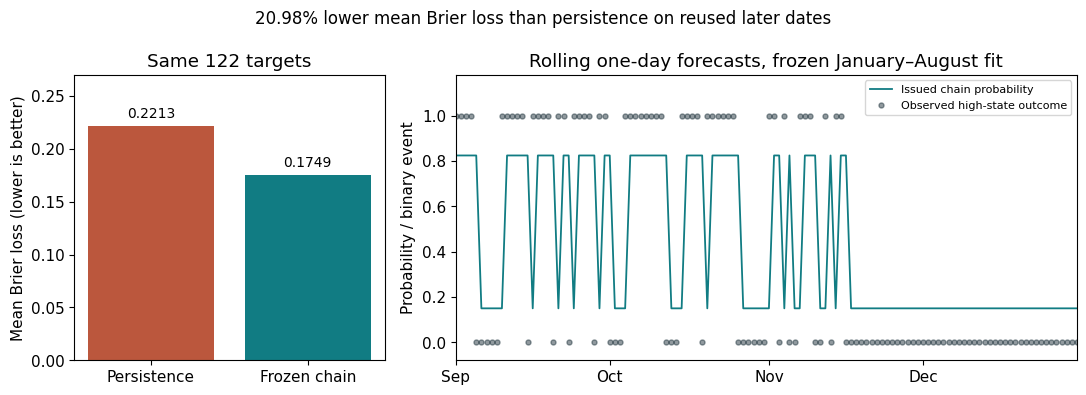

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 2]})
bars = axes[0].bar(["Persistence", "Frozen chain"], [baseline_brier, chain_brier], color=["#bb573d", "#117c83"])
axes[0].bar_label(bars, fmt="%.4f", padding=4, fontsize=10)
axes[0].set(ylim=(0, 0.27), ylabel="Mean Brier loss (lower is better)", title="Same 122 targets")
axes[1].plot(bike.dteday.iloc[CUTOFF:], probability, color="#117c83", linewidth=1.3, label="Issued chain probability")
axes[1].scatter(bike.dteday.iloc[CUTOFF:], actual, color="#243740", s=13, alpha=0.5, label="Observed high-state outcome")
axes[1].set(xlim=(pd.Timestamp("2011-09-01"), pd.Timestamp("2011-12-31")), ylim=(-0.08, 1.18), ylabel="Probability / binary event", title="Rolling one-day forecasts, frozen January–August fit")
axes[1].xaxis.set_major_locator(mdates.MonthLocator()); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
axes[1].legend(loc="upper right", fontsize=8, ncol=1)
fig.suptitle(f"{relative_gain:.2f}% lower mean Brier loss than persistence on reused later dates", fontsize=12)
fig.tight_layout(); plt.show()

**Figure 2. One event-probability comparison, with its information rule visible.** The event is at least 4000 completed system rentals/day. Left: zero-based bars compare frozen-chain and persistence mean Brier loss on the same 122 September–December 2011 targets. Right: each chain probability uses the prior observed state and the matrix fitted to 242 January–August transitions. The absolute score reduction is 0.0464244, or 20.976959% relative to persistence. This is a descriptive comparison on reused development dates; it does not establish future superiority, count accuracy, or capacity effects.

Before continuing: which element of the figure lets a reader verify that a statement about “21%” concerns a loss rather than an event probability? What uncertainty information is still absent?

## 4. Explain one forecast without hiding behind the notebook
For any selected target, trace **previous date/count/state → frozen row → issued probability → revealed outcome → loss**. Do not use the target count to choose the forecast row.

The independent hand fixture
$$P=\begin{pmatrix}0.8&0.2\\0.3&0.7\end{pmatrix},\quad P(S_2=1\mid S_0=0)=0.8(0.2)+0.2(0.7)=0.30$$
gives a two-step probability. If the subsequently observed binary outcome is 1, probability forecasts 0.30 and 0 have losses $0.49$ and $1$, respectively. The event probability, one outcome's loss, and a many-target mean-loss difference are different quantities.

In [9]:
trace_rows = []
for date in ["2011-09-01", "2011-10-01", "2011-11-01", "2011-12-01"]:
    t = bike.index[bike.dteday.eq(date)][0]; k = t-CUTOFF
    trace_rows.append(dict(target=date, previous_date=str(bike.dteday.iloc[t-1].date()),
        previous_count=int(counts[t-1]), previous_state=int(states[t-1]), issued_probability=probability[k],
        revealed_state=int(actual[k]), chain_loss=chain_loss[k], persistence_loss=baseline_loss[k]))
trace = pd.DataFrame(trace_rows); display(trace)
assert np.isclose(0.8*0.2+0.2*0.7, 0.30)
assert np.isclose((0.30-1)**2, 0.49) and (0-1)**2 == 1
print("Explain one row aloud; the target's outcome is used only for scoring.")

,target,previous_date,previous_count,previous_state,issued_probability,revealed_state,chain_loss,persistence_loss
0,2011-09-01,2011-08-31,5058,1,0.824074,1,0.030950,0.0
1,2011-10-01,2011-09-30,5202,1,0.824074,0,0.679098,1.0
2,2011-11-01,2011-10-31,3669,0,0.149254,1,0.723769,1.0
3,2011-12-01,2011-11-30,3613,0,0.149254,0,0.022277,0.0


Explain one row aloud; the target's outcome is used only for scoring.


**Information-boundary check.** Flip the September 18 target state. Its own issued forecast must stay unchanged. Only the next day's predictor can change in this frozen one-lag model; its scored outcome changes immediately. This verifies the declared information rule for the implementation, not the Markov or homogeneity assumptions.

In [10]:
changed = counts.copy(); target = 260; position = target-CUTOFF
changed[target] = 0 if counts[target] >= THRESHOLD else THRESHOLD
changed_P, changed_q, changed_b, changed_y = rolling_forecasts(changed)
assert np.array_equal(changed_P, P)
assert np.array_equal(changed_q[:position+1], probability[:position+1])
assert np.flatnonzero(changed_q != probability).tolist() == [position+1]
assert np.flatnonzero(changed_b != persistence).tolist() == [position+1]
assert changed_y[position] != actual[position]
print("PASS: future-state flip preserves its own issued forecast and changes only the next predictor.")

PASS: future-state flip preserves its own issued forecast and changes only the next predictor.


## 5. Communicate a scenario as a conditional calculation
Write $a=\widehat P_{01}$ and $b=\widehat P_{10}$. Change only the low-to-high probability by an assumed multiplier $c$:
$$P(c)=\begin{pmatrix}1-ca&ca\\b&1-b\end{pmatrix},\qquad p_7(c)=[P(c)^7]_{01}.$$
Starting low, this is the exact probability of a high state after seven transitions **conditional on the selected matrix**. Reject $ca>1$; silently clipping would change the declared scenario. Holding $b$ fixed is an assumption. Predict the direction of the calculation for $c=0.5,1,1.5$ before executing.

A probability change is expressed as $100[p_7(c)-p_7(1)]$ **percentage points**. This change is neither an observed intervention effect nor automatically beneficial; “high” means many completed rentals, not unmet demand.

In [11]:
def scenario_matrix(P, factor):
    P = np.asarray(P, float)
    if P.shape != (2, 2) or not np.isfinite(P).all(): raise ValueError("Finite 2 by 2 matrix required")
    if np.any(P < 0) or np.any(P > 1) or not np.allclose(P.sum(axis=1), 1, atol=1e-12, rtol=0):
        raise ValueError("Transition rows must be probabilities summing to one")
    if not np.isfinite(factor) or factor < 0: raise ValueError("Finite nonnegative factor required")
    a, b = factor*P[0, 1], P[1, 0]
    if a > 1: raise ValueError("Scenario low-to-high probability exceeds one")
    return np.array([[1-a, a], [b, 1-b]])
factors = np.array([0.5, 1.0, 1.5])
scenario_prob = np.array([np.linalg.matrix_power(scenario_matrix(P, c), 7)[0, 1] for c in factors])
change_pp = 100*(scenario_prob-scenario_prob[1])

In [12]:
scenario_table = pd.DataFrame({"Factor on low-to-high probability": factors,
    "Exact high-state probability at 7 transitions": scenario_prob,
    "Change from reference (percentage points)": change_pp})
display(scenario_table)
assert np.allclose(scenario_prob, [0.2582955186235272, 0.4297389886172236, 0.5442612873363228])
assert all(scenario_matrix(P, c)[1, 0] == P[1, 0] for c in factors)
assert np.isclose(np.linalg.matrix_power([[0.8, 0.2], [0.3, 0.7]], 2)[0, 1], 0.30)

,Factor on low-to-high probability,Exact high-state probability at 7 transitions,Change from reference (percentage points)
0,0.5,0.258296,-17.144347
1,1.0,0.429739,0.000000
2,1.5,0.544261,11.452230


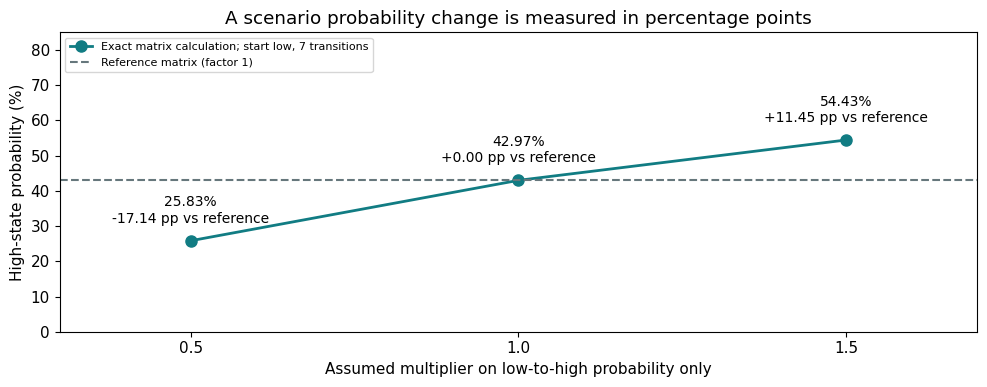

In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(factors, 100*scenario_prob, "o-", color="#117c83", linewidth=2, markersize=8, label="Exact matrix calculation; start low, 7 transitions")
ax.axhline(100*scenario_prob[1], color="#66777c", linestyle="--", label="Reference matrix (factor 1)")
for c, p, delta in zip(factors, scenario_prob, change_pp):
    ax.annotate(f"{100*p:.2f}%\n{delta:+.2f} pp vs reference", (c, 100*p), xytext=(0, 13), textcoords="offset points", ha="center", fontsize=10)
ax.set(xlim=(0.3, 1.7), ylim=(0, 85), xticks=factors, xlabel="Assumed multiplier on low-to-high probability only", ylabel="High-state probability (%)", title="A scenario probability change is measured in percentage points")
ax.legend(loc="upper left", fontsize=8); fig.tight_layout(); plt.show()

**Figure 3. Exact probabilities under three assumed matrices.** The start is low and the horizon is seven transitions. The reference probability is 42.97%; factors 0.5 and 1.5 produce 25.83% and 54.43%, changes of −17.14 and +11.45 percentage points. High-to-low probability remains fixed. These are calculated probabilities, with no Monte Carlo draw error in the plotted values; the plot contains no confidence intervals. Fitted-parameter uncertainty, model adequacy, and the meaning of the unmeasured multiplier remain unresolved. The connecting line guides the eye among the three displayed scenarios.

### More paths address one uncertainty source
If we instead simulated $N$ independent terminal indicators from a fixed scenario matrix, the **oracle conditional Monte Carlo standard error** would be
$$\operatorname{SE}(\widehat p\mid P(c))=\sqrt{\frac{p_7(c)[1-p_7(c)]}{N}}\le\frac1{2\sqrt N}.$$
The table below is a calculated precision reference, not a simulation and not a new bike dataset. It describes a hypothetical independent-path estimator. Multiplying the probability-scale SE by 100 expresses it in percentage points. It omits transition-estimation uncertainty, structural uncertainty, and the lack of causal identification. Exact matrix calculation removes this computational error; it does not remove those other uncertainties.

In [14]:
replications = np.array([100, 1000, 10000])
p_reference = scenario_prob[1]
precision_reference = pd.DataFrame({"Hypothetical independent paths": replications,
    "Oracle conditional MCSE (probability)": np.sqrt(p_reference*(1-p_reference)/replications),
    "Oracle conditional MCSE (percentage points)": 100*np.sqrt(p_reference*(1-p_reference)/replications),
    "Universal MCSE bound (probability)": 1/(2*np.sqrt(replications))})
display(precision_reference)
assert np.all(precision_reference.iloc[:, 1] <= precision_reference.iloc[:, 3])

,Hypothetical independent paths,Oracle conditional MCSE (probability),Oracle conditional MCSE (percentage points),Universal MCSE bound (probability)
0,100,0.049504,4.950388,0.050000
1,1000,0.015655,1.565450,0.015811
2,10000,0.004950,0.495039,0.005000


## 6. Fit the evidence into six minutes
Use six connected sections: **question and units → data and assumptions → model and check → evidence and baseline → scenarios and uncertainty → recommendation and limits**. The suggested budget below totals 360 seconds; move time to suit the project and audience. It is a rehearsal aid, not an automated grade or readiness score. Questions follow the six-minute talk; no fixed question period is imposed here.

For a technical audience, trace the fitted row or loss calculation. For a decision audience, emphasize what is measured, what action is being considered, and what the evidence cannot distinguish. Change the wording and emphasis, not the numbers, units, information limits, or degree of certainty.

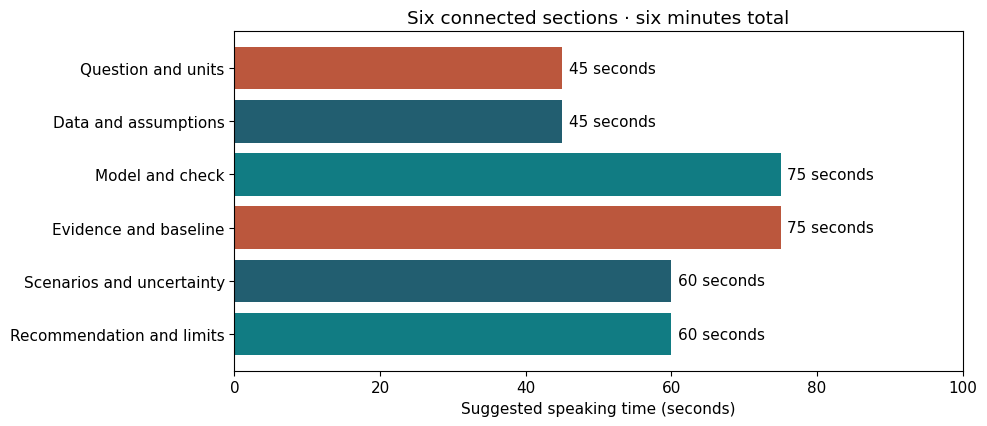

In [15]:
section_names = ["Question and units", "Data and assumptions", "Model and check", "Evidence and baseline", "Scenarios and uncertainty", "Recommendation and limits"]
seconds = np.array([45, 45, 75, 75, 60, 60])
assert seconds.sum() == 360
fig, ax = plt.subplots(figsize=(10, 4.4))
bars = ax.barh(section_names[::-1], seconds[::-1], color=["#117c83", "#225e70", "#bb573d", "#117c83", "#225e70", "#bb573d"])
ax.bar_label(bars, labels=[f"{x} seconds" for x in seconds[::-1]], padding=5)
ax.set(xlim=(0, 100), xlabel="Suggested speaking time (seconds)", title="Six connected sections · six minutes total")
fig.tight_layout(); plt.show()

**Figure 4. A flexible narrative budget.** The six suggested sections total 360 seconds. These are planned speaking times, not observed student performance or scoring weights. Keep at least one reproducible calculation, a baseline comparison, and a limitation visible; use rehearsal to redistribute time.

A compact **claim–evidence ledger** makes the story inspectable:

| Claim | Evidence type and location | Boundary or limitation |
| --- | --- | --- |
| We observed 365 complete daily counts | Observed: bundled CSV; data checks above | Completed rentals, not unmet demand |
| Chain mean Brier loss is lower than persistence here | Calculated: common-target scores and Figure 2 | Reused 2011 development period; descriptive comparison |
| Factor 1.5 gives 54.43% high-state probability at seven transitions | Calculated conditional on assumed matrix: Figure 3 | Fixed high-to-low probability; not an identified intervention |
| 10,000 independent paths would have small conditional MCSE | Calculated precision reference above | No paths drawn here; no model-uncertainty guarantee |

For an individual explanation, define the symbol and units, trace one calculation, identify its check and assumption, modify one assumption, and admit a material limit. If a question exceeds your evidence, say what additional measurement or check would be needed.

## 7. Carry a compact, replayable result record
This in-memory summary records the data, configuration, software, and central numerical results. It creates no output files. Module 13's source-fingerprint and fuller reproducibility recipe remain available for the existing project package. No stochastic draws occur in this notebook, so a random seed would not affect its computations. Fresh-kernel verification tests hidden state; it does not validate every untested environment or scientific assumption.

In [16]:
record = dict(data=dict(sha256=data_sha256, rows=len(bike), units=source["units"]["cnt"],
    doi=source["doi"], license=source["license"]),
    configuration=dict(threshold=THRESHOLD, inclusive=True, train_end="2011-08-31", targets=122,
    forecast="frozen matrix, previous observed state", horizon=7, start=0, factors=factors.tolist()),
    software=dict(python=platform.python_version(), packages={p: metadata.version(p) for p in ["numpy", "pandas", "matplotlib", "nbformat", "nbclient"]}),
    results=dict(transition_counts=N.tolist(), transition_matrix=P.tolist(), chain_brier=float(chain_brier),
    persistence_brier=float(baseline_brier), absolute_loss_reduction=float(absolute_gain),
    relative_loss_reduction_percent=float(relative_gain), scenario_probabilities=scenario_prob.tolist()),
    computation="deterministic; no simulation or RNG", verification="README.md#maintain-and-verify")
print(json.dumps(record, indent=2))

{
  "data": {
    "sha256": "fb9790e24f07b237431b89c787a24ed8e97c365437a86f7161269df9452b2329",
    "rows": 365,
    "units": "completed rentals per calendar day (not unique bicycles or latent demand)",
    "doi": "10.24432/C5W894",
    "license": "CC BY 4.0"
  },
  "configuration": {
    "threshold": 4000,
    "inclusive": true,
    "train_end": "2011-08-31",
    "targets": 122,
    "forecast": "frozen matrix, previous observed state",
    "horizon": 7,
    "start": 0,
    "factors": [
      0.5,
      1.0,
      1.5
    ]
  },
  "software": {
    "python": "3.10.9",
    "packages": {
      "numpy": "1.24.2",
      "pandas": "2.0.0",
      "matplotlib": "3.7.1",
      "nbformat": "5.7.0",
      "nbclient": "0.5.13"
    }
  },
  "results": {
    "transition_counts": [
      [
        114,
        20
      ],
      [
        19,
        89
      ]
    ],
    "transition_matrix": [
      [
        0.8507462686567164,
        0.14925373134328357
      ],
      [
        0.1759259259259259

## 8. Optional AI-output verification
The following overclaim is **instructor-written**, not retrieved AI output. Audit it whether or not you use AI; no account or paid service is needed.

> Our Markov model is 21% more accurate, so increasing low-to-high transitions by 50% will prevent bike shortages. With 10,000 simulations, all uncertainty is negligible; the reused later period proves future performance.

Check each link between a number and its interpretation. Use the displayed arithmetic, information rule, data units, scenario definition, and uncertainty decomposition as independent evidence. Asking another model to agree is not an independent mathematical check. Keep consequential assistance and your corrections visible, and be ready to explain all submitted work.

## 9. Four investigations · final project rehearsal
The cells below remain unanswered. They refine the existing deliverables and individual explanation; they do not assign another concept lab or project.

### E1 — Build a six-minute evidence narrative
For the existing project, outline six minutes of speaking time across question and units, data and assumptions, model and check, evidence and baseline, scenarios and uncertainty, and recommendation and limits. Build a claim–evidence ledger for three central claims, labeling evidence as observed, calculated, simulated, or assumed. Keep the project's two or three meaningful methods visible; no new project or extra submission is assigned.

In [17]:
# YOUR WORK — E1
# Add your calculation, evidence, and short interpretation here.

### E2 — Make the central figure defensible
Reproduce one central project figure from a fresh kernel and write a stand-alone caption naming the target, units, data roles, baseline, and a decision-relevant limitation. Hand-check an absolute and a relative loss comparison, including the zero-baseline boundary. Explain why a percentage reduction in mean Brier loss is not a percentage increase in accuracy or a percentage-point change in event probability.

In [18]:
# YOUR WORK — E2
# Add your calculation, evidence, and short interpretation here.

### E3 — Explain and modify your own calculation
Prepare an individual explanation of one formula and the code that implements it: define the symbols, target, units, and available information; trace one numerical calculation; name an independent check; then change one assumption and predict the direction or limits of the result before rerunning. Distinguish a conditional scenario comparison from an observed or causal effect, and computational uncertainty from model uncertainty.

In [19]:
# YOUR WORK — E3
# Add your calculation, evidence, and short interpretation here.

### E4 — Audit the claim and finish the existing package
Audit the provided instructor-written AI-style overclaim without requiring an AI account. For each consequential claim, record independent evidence, a correction, and a remaining limitation. Check consistency across the existing executed notebook, 4–5-page report, one-page decision brief, and slides; document contributions and consequential assistance, and rehearse the six-minute talk and individual explanation. This is a final review of existing deliverables, not an additional assignment.

In [20]:
# YOUR WORK — E4
# Add your calculation, evidence, and short interpretation here.

## 10. Optional extension and course close
Exchange one central figure and its notebook recipe with a partner, or revisit them yourself after a break. Ask the reader to restate the target, information boundary, comparison, and limitation, then reproduce the figure from a fresh kernel. Revise language that allows an unsupported interpretation. This is optional rehearsal, not a new submission requirement.

Complete the existing executed notebook, 4–5-page report, one-page decision brief, and slides; rehearse the six-minute presentation plus questions and your individual explanation. The existing individual-explanation component remains 6% within the 10% explanation-and-participation category. No new rubric weights are introduced. The fourteen-module course ends here.

References and provenance: [UCI Bike Sharing](https://doi.org/10.24432/C5W894), Fanaee-T (2013), CC BY 4.0. The supplied MATH 6241 notes and earlier modules provide the finite-state Markov-chain, multistep probability, and Monte Carlo context. Modules 12–13 establish the reused validation and reproducibility workflow. The presentation rehearsal and claim–evidence ledger are applied teaching activities, not a new stochastic-process family or a claim that the supplied notes prescribe this presentation format.

Scoring reference: Gneiting and Raftery (2007), [Strictly Proper Scoring Rules, Prediction, and Estimation](https://doi.org/10.1198/016214506000001437) ([author-hosted PDF](https://sites.stat.washington.edu/raftery/Research/PDF/Gneiting2007jasa.pdf)). The author copy provides an access alternative to the DOI landing page.
